In [1]:
import pandas as pd
import matplotlib.pyplot as plt



# Load the cleaned Netflix dataset

Dataset loaded successfully!
Total titles: 8807


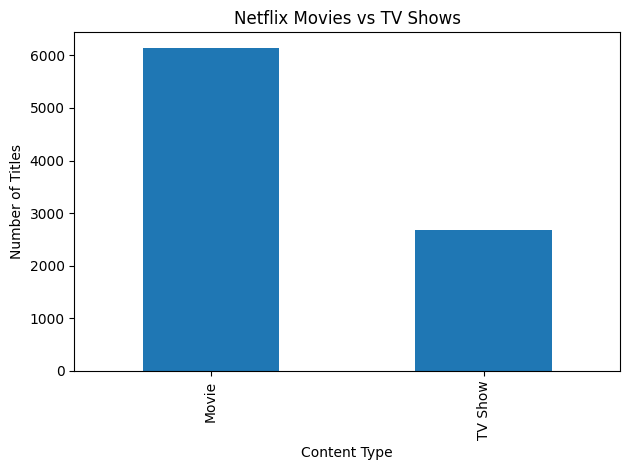

In [2]:
df = pd.read_csv("netflix_cleaned.csv")

print("Dataset loaded successfully!")
print("Total titles:", len(df))

# Chart 1: Movies vs TV Shows
df["type"].value_counts().plot(kind="bar")
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("content_types.png")
plt.show()

# Chart 2: Netflix titles by release year


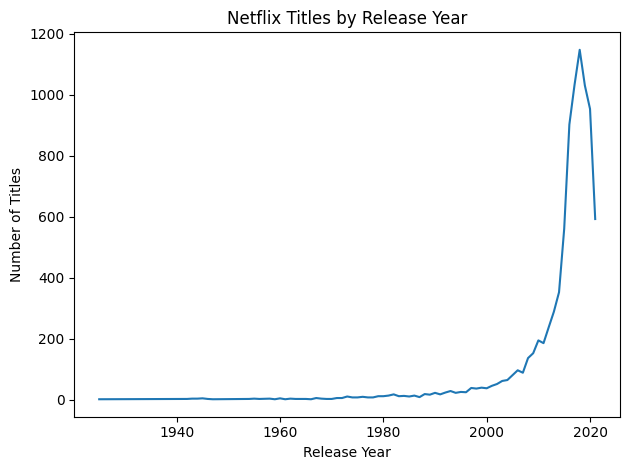

In [3]:
df["release_year"].value_counts().sort_index().plot(kind="line")
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("content_by_year.png")
plt.show()



# Content Ratings Distribution

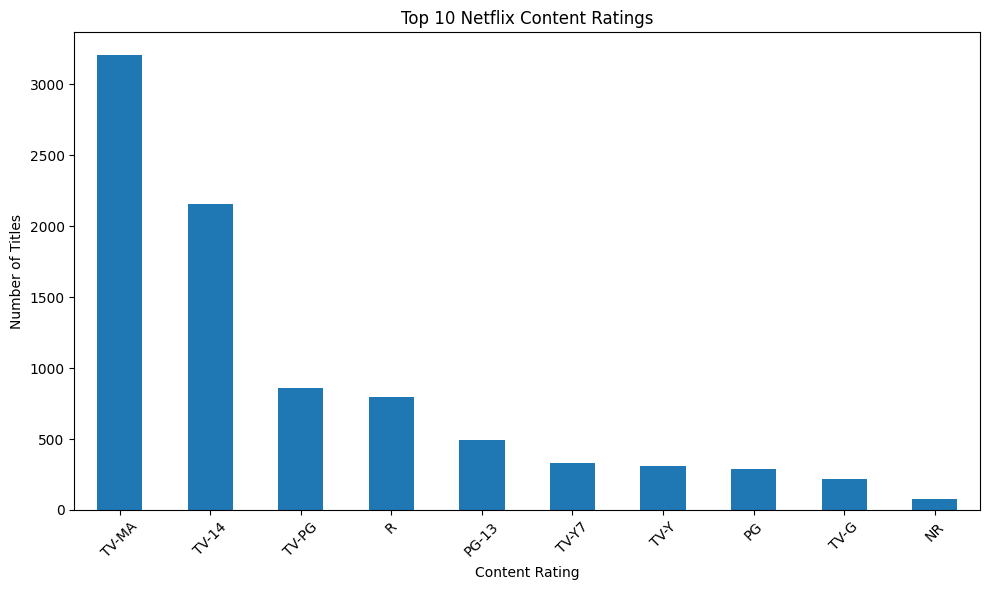

In [4]:
rating_counts = df['rating'].value_counts().head(10)

plt.figure(figsize=(10, 6))
rating_counts.plot(kind='bar')

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("content_ratings.png")
plt.show()


# Content Type by Rating

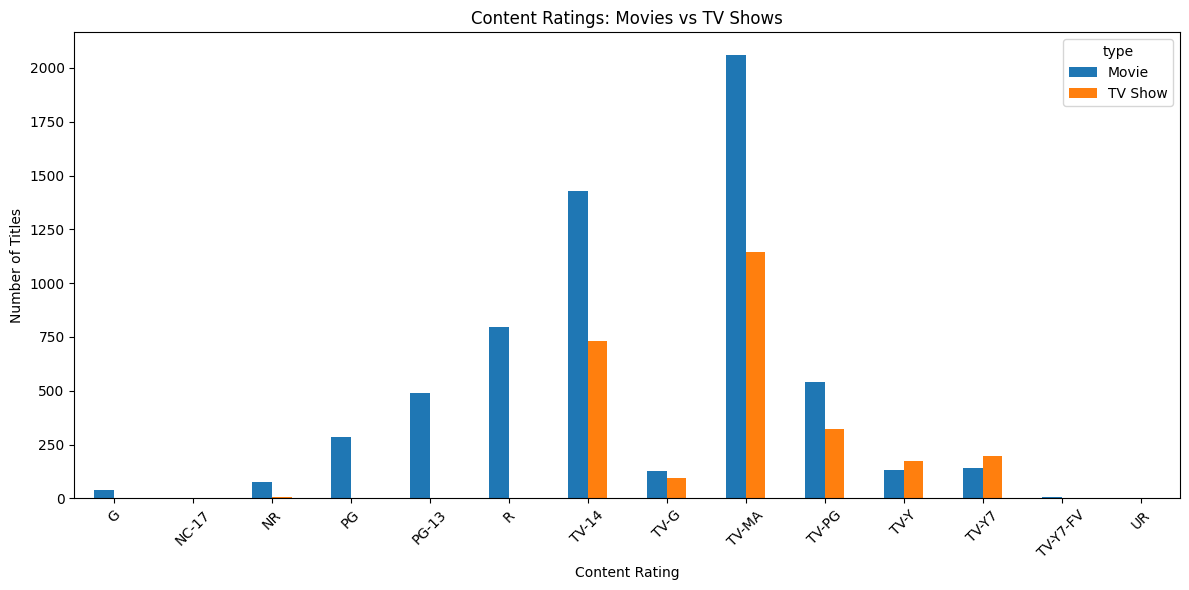

In [5]:
rating_data = df.dropna(subset=['type', 'rating'])

rating_counts = rating_data.groupby(['rating', 'type']).size().unstack(fill_value=0)

rating_counts.plot(kind='bar', figsize=(12, 6))

plt.title('Content Ratings: Movies vs TV Shows')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('ratings_by_type.png')
plt.show()

# Directors with the most titles on Netflix

Top 10 Directors with the Most Netflix Titles:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Martin Scorsese        12
Youssef Chahine        12
Jay Chapman            12
Name: count, dtype: int64


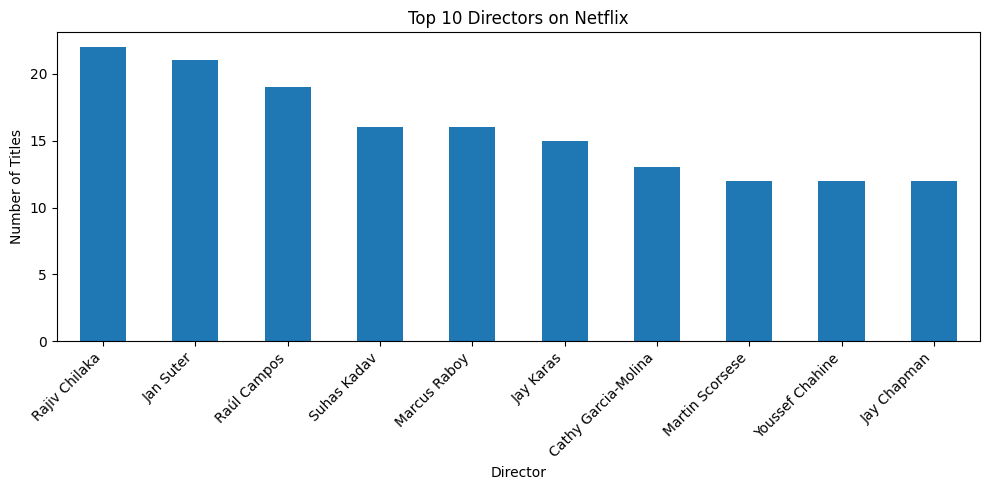

In [6]:
director_data = df[df["director"].notna()].copy()

director_data["director"] = director_data["director"].str.split(", ")
director_data = director_data.explode("director")

director_data["director"] = director_data["director"].str.strip()

director_data = director_data[
    (director_data["director"] != "") &
    (director_data["director"].str.lower() != "unknown")
]

top_directors = director_data["director"].value_counts().head(10)

print("Top 10 Directors with the Most Netflix Titles:")
print(top_directors)

top_directors.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Directors on Netflix")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()